In [1]:
import sys
import os
import pandas as pd
import numpy as np

In [ ]:
# configuracióo de rutas
RUTA_NOTEBBOK = os.getcwd()
RUTA_PROYECTO = os.path.abspath(os.path.join(RUTA_NOTEBBOK, '..'))
RUTA_SCRIPT_ETL = os.path.join(RUTA_PROYECTO, 'etl')
RUTA_DATA_RAW = os.path.join(RUTA_PROYECTO, 'data', 'raw')

if RUTA_SCRIPT_ETL not in sys.path:
    sys.path.append(RUTA_SCRIPT_ETL)
    
# Importar las funciones de extracción
if RUTA_PROYECTO not in sys.path:
    sys.path.insert(0, RUTA_PROYECTO)

from etl.extract import (
    extraer_vigilantes,
    extraer_emp_seg,
    extraer_objetivos,
    extraer_obj_vig,
    extraer_salida,
)
# Configuración de visualización de pandas
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 50)
pd.set_option('display.max_colwidth', 40)
pd.set_option('display.width', 1000)
pd.set_option('display.float_format', '{:.2f}'.format)
print('✅ Configuración completa')

ModuleNotFoundError: No module named 'etl'

In [4]:
# Carga de datos
df_vigilantes = extraer_vigilantes(os.path.join(RUTA_DATA_RAW, 'Vigilantes.csv'))
df_empresas = extraer_emp_seg(os.path.join(RUTA_DATA_RAW, 'Empresas.csv'))
df_objetivos = extraer_objetivos(os.path.join(RUTA_DATA_RAW, 'OBJETIVOS.csv'))
df_obj_vig = extraer_obj_vig(os.path.join(RUTA_DATA_RAW, 'ObjetivosVigilantes.csv'))
df_salida = extraer_salida(os.path.join(RUTA_DATA_RAW, 'Salida.csv'))

print(f'✅ Vigilantes: {df_vigilantes.shape[0]:4d} filas x  {df_vigilantes.shape[1]} columnas')
print(f'✅ Empresas: {df_empresas.shape[0]:4d} filas x  {df_empresas.shape[1]} columnas')
print(f'✅ Objetivos: {df_objetivos.shape[0]:4d} filas x  {df_objetivos.shape[1]} columnas')
print(f'✅ ObjetivosVigilantes: {df_obj_vig.shape[0]:4d} filas x  {df_obj_vig.shape[1]} columnas')
print(f'✅ Salida: {df_salida.shape[0]:4d} filas x  {df_salida.shape[1]} columnas')


NameError: name 'extraer_objetivos' is not defined

In [6]:
# Dimensiones y estructura de los DataFrames

def explorar_estructura(df, nombre_df):
    '''Muestra la estructura básica de un DataFrame'''
    print('\n' + '='*70)
    print(f'�� {nombre_df}')
    print('='*70)
    print(f' Filas: {df.shape[0]}')
    print(f' Columnas: {df.shape[1]}')
    print(f' Memoria: {df.memory_usage(deep=True).sum() / 1024:.2f} KB')
    print(f'\n Columnas y tipos de datos:')
    for i, (col, tipo) in enumerate(df.dtypes.items(), 1):
        print(f' {i:2d}. {col:<25} → {tipo}')


explorar_estructura(df_vigilantes, 'Vigilantes')
explorar_estructura(df_empresas, 'Empresas')


�� Vigilantes
 Filas: 1754
 Columnas: 6
 Memoria: 184.75 KB

 Columnas y tipos de datos:
  1. DNI                       → int64
  2. Apellido                  → str
  3. Nombres                   → str
  4. Empresas                  → str
  5. Estado                    → str
  6. Ftramite                  → str

�� Empresas
 Filas: 40
 Columnas: 9
 Memoria: 8.73 KB

 Columnas y tipos de datos:
  1. Empresa                   → str
  2. Dir_Responsable           → str
  3. DomEmpresa                → str
  4. Cuit                      → str
  5. N°_Exp                    → str
  6. Codigo_Policial           → str
  7. Con Res de Habilitacion   → str
  8. Res Ministerial           → str
  9. Fecha de Notificacion     → str


In [7]:
# Análisis de valores nulos
def analizar_nulos(df, nombre):
    '''Analiza los valores nulos de un DataFrame'''
    print('\n' + '='*70)
    print(f'��️ NULOS EN {nombre}')
    print('='*70)
    
    nulos = df.isnull().sum()
    total_filas = len(df)
    
    # Crear tabla resumen
    resumen = pd.DataFrame({
        'Nulos': nulos,
        'Porcentaje': (nulos / total_filas * 100).round(2),
        'Tipo': df.dtypes
    })
    resumen = resumen[resumen['Nulos'] > 0].sort_values('Nulos', ascending=False)
    if len(resumen) == 0:
        print(' ✅ No hay valores nulos')
    else:
        print(f' ⚠️ {len(resumen)} columnas con nulos de {df.shape[1]} totales')
        print(f' Total de valores nulos: {nulos.sum()}')
        print()
        print(resumen.to_string())
    
    return resumen

nulos_vigilantes = analizar_nulos(df_vigilantes, 'Vigilantes')
nulos_empresas = analizar_nulos(df_empresas, 'Empresas')


��️ NULOS EN Vigilantes
 ⚠️ 5 columnas con nulos de 6 totales
 Total de valores nulos: 56

          Nulos  Porcentaje Tipo
Ftramite     34        1.94  str
Empresas     14        0.80  str
Estado        4        0.23  str
Nombres       3        0.17  str
Apellido      1        0.06  str

��️ NULOS EN Empresas
 ⚠️ 8 columnas con nulos de 9 totales
 Total de valores nulos: 55

                         Nulos  Porcentaje Tipo
Fecha de Notificacion       12       30.00  str
N°_Exp                       9       22.50  str
Codigo_Policial              9       22.50  str
Con Res de Habilitacion      9       22.50  str
Res Ministerial              9       22.50  str
Dir_Responsable              3        7.50  str
DomEmpresa                   3        7.50  str
Cuit                         1        2.50  str


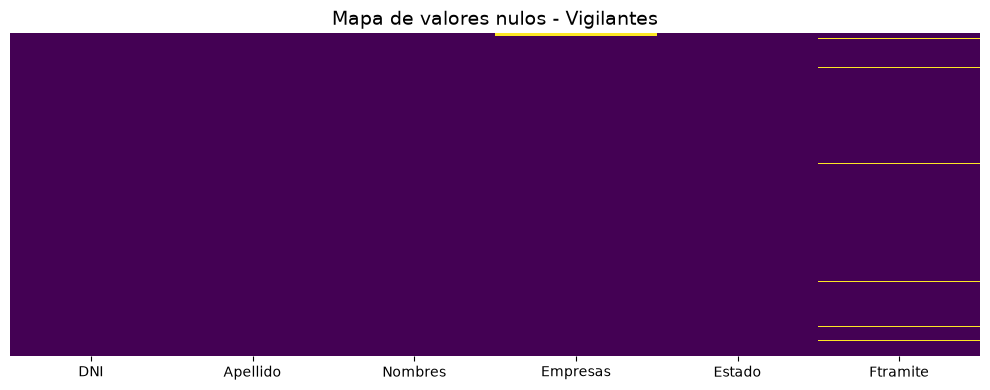

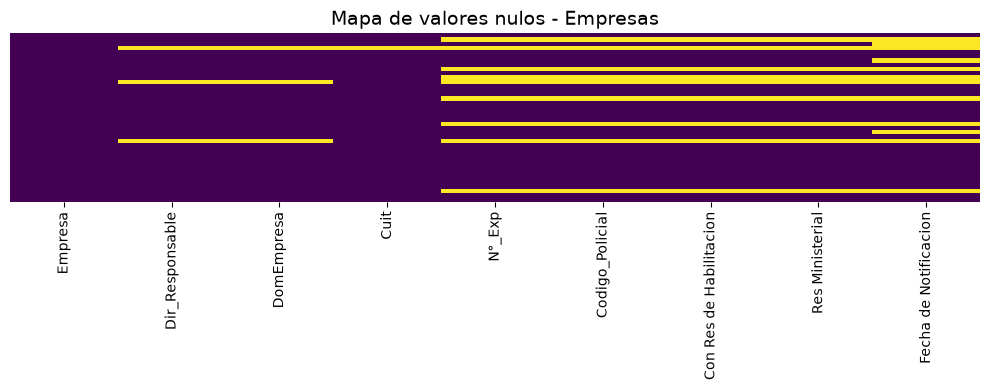

In [9]:
# Visualización de nulos
import matplotlib.pyplot as plt
import seaborn as sns

def visualizar_nulos(df, nombre):
    '''Muestra un mapa de calor de valores nulos'''
    fig, ax = plt.subplots(figsize=(10, 4))
    sns.heatmap(df.isnull(), cbar=False, cmap='viridis', yticklabels=False, ax=ax)
    ax.set_title(f'Mapa de valores nulos - {nombre}', fontsize=14)
    plt.tight_layout()
    plt.show()
    
visualizar_nulos(df_vigilantes, 'Vigilantes')
visualizar_nulos(df_empresas, 'Empresas')


In [20]:
# Análisis de duplicados

def analizar_duplicados(df, nombre, columna_clave=None):
    '''Analiza los duplicados en un DataFrame'''
    print('\n' + '='*70)
    print(f'�� DUPLICADOS EN {nombre}')
    print('='*70)
    
    # Duplicados exactos (todas las columnas iguales)
    duplicados_exactos = df.duplicated().sum()
    print(f' Duplicados exactos (todas las columnas): {duplicados_exactos}')
    
    # Duplicados por columna clave
    if columna_clave and columna_clave in df.columns:
        duplicados_clave = df.duplicated(subset=columna_clave).sum()
        print(f" Duplicados por '{columna_clave}': {duplicados_clave}")
        if duplicados_clave > 0:
            print(f"\n Ejemplos de duplicados por '{columna_clave}':")
            dup_df = df[df.duplicated(subset=columna_clave, keep=False)]
            print(dup_df.sort_values(columna_clave).head(10).to_string())
    
    return duplicados_exactos

# Analizar dataframes
analizar_duplicados(df_vigilantes, 'Vigilantes', columna_clave='DNI')
analizar_duplicados(df_empresas, 'Empresas', columna_clave='Empresa')


�� DUPLICADOS EN Vigilantes
 Duplicados exactos (todas las columnas): 0
 Duplicados por 'DNI': 0

�� DUPLICADOS EN Empresas
 Duplicados exactos (todas las columnas): 0
 Duplicados por 'Empresa': 0


np.int64(0)